# StegaStamp: a small demo


In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path("..").resolve()))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image

from api.transformers.stegastamp_watermark import StegaStampWatermarkTransformer

payload = "CVPR20!"
device = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")

transformer = StegaStampWatermarkTransformer(
    seed=2026,
    device=device,
    model_dtype=torch.float32,
    model_id="vadishev/stegastamp-original",
    model_revision="b89ef7cdd9dd16cbdadb5ff5da971858789208b4",
    default_payload=payload,
)

## Images (Fox, Cat, Dog), encoder residual, and pixel difference


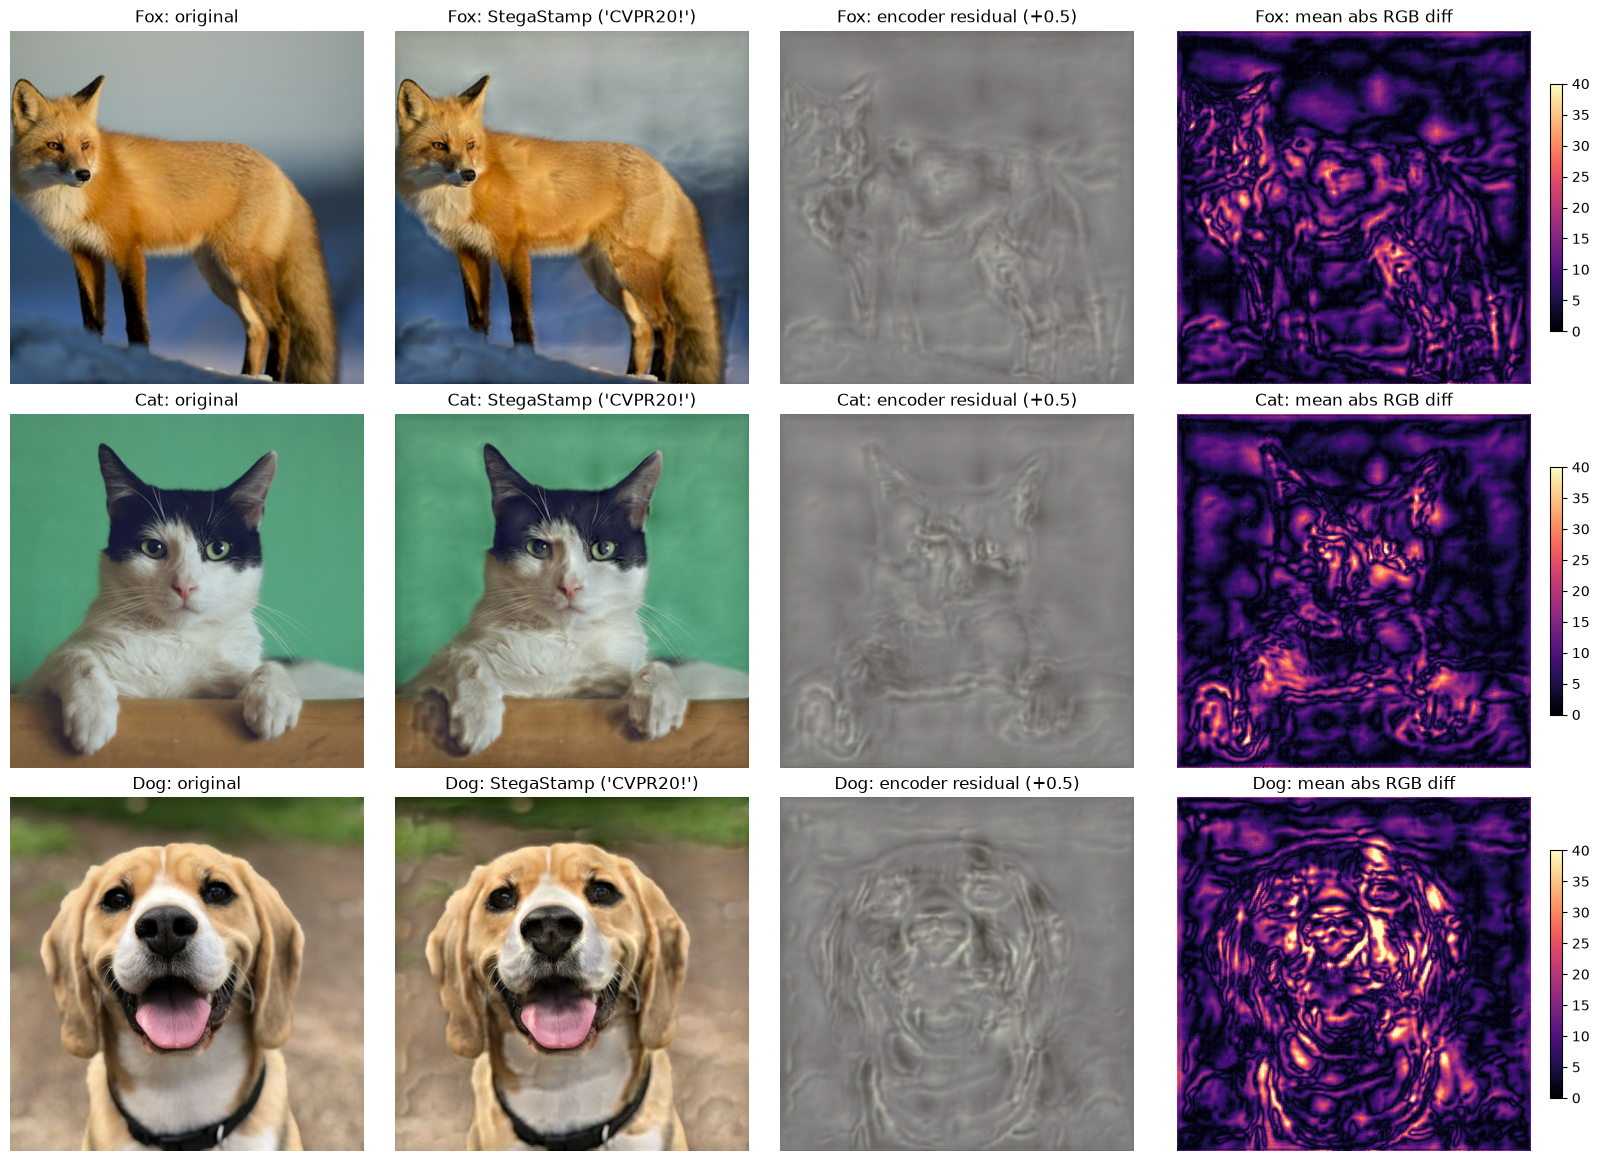

In [2]:
assets_dir = Path("..") / "docs" / "assets" / "stegastamp"
samples = {
    "Fox": Image.open(assets_dir / "fox.png").convert("RGB"),
    "Cat": Image.open(assets_dir / "cat.png").convert("RGB"),
    "Dog": Image.open(assets_dir / "dog.png").convert("RGB"),
}

marked_samples = {}
residuals = {}
fig, axes = plt.subplots(len(samples), 4, figsize=(16, 11.5), constrained_layout=True)

for row, (label, img_plain) in enumerate(samples.items()):
    img_marked, res = transformer.embed(img_plain, payload)
    marked_samples[label] = img_marked
    residuals[label] = res

    diff = np.abs(
        np.asarray(img_marked, dtype=np.float32)
        - np.asarray(img_plain, dtype=np.float32)
    ).mean(axis=2)
    res_vis = (res[0].permute(1, 2, 0).numpy() + 0.5).clip(0.0, 1.0)

    axes[row, 0].imshow(img_plain)
    axes[row, 0].set_title(f"{label}: original")
    axes[row, 1].imshow(img_marked)
    axes[row, 1].set_title(f"{label}: StegaStamp ('{payload}')")
    axes[row, 2].imshow(res_vis)
    axes[row, 2].set_title(f"{label}: encoder residual (+0.5)")
    heatmap = axes[row, 3].imshow(diff, cmap="magma", vmin=0, vmax=40)
    axes[row, 3].set_title(f"{label}: mean abs RGB diff")
    fig.colorbar(heatmap, ax=axes[row, 3], shrink=0.7)
    for ax in axes[row]:
        ax.axis("off")

plt.show()

## Physical display-imaging perturbation pipeline

StegaStamp simulates real-world printing and camera capture via perspective warp, motion/defocus blur, color manipulation, Gaussian noise, and differentiable JPEG compression.


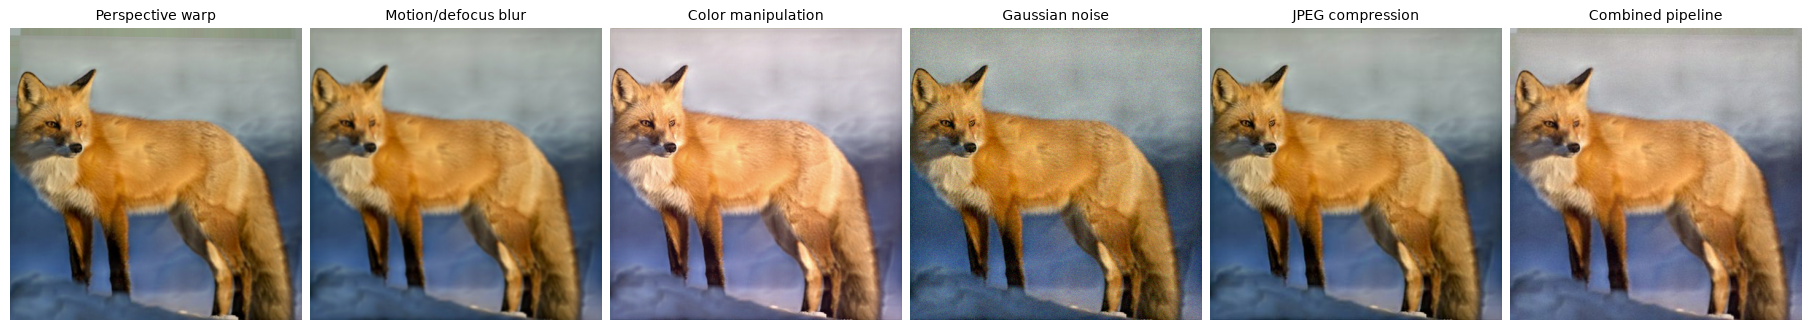

In [3]:
image_marked = marked_samples["Fox"]

perturbation_stages = [
    ("Perspective warp", transformer.apply_perturbation(image_marked, kind="warp", strength=0.6)),
    ("Motion/defocus blur", transformer.apply_perturbation(image_marked, kind="blur", strength=0.6)),
    ("Color manipulation", transformer.apply_perturbation(image_marked, kind="color", strength=0.6)),
    ("Gaussian noise", transformer.apply_perturbation(image_marked, kind="noise", strength=0.6)),
    ("JPEG compression", transformer.apply_perturbation(image_marked, kind="jpeg", strength=0.6)),
    ("Combined pipeline", transformer.apply_perturbation(image_marked, kind="all", strength=0.6)),
]

fig, axes = plt.subplots(1, 6, figsize=(18, 3.3), constrained_layout=True)
for ax, (title, img_corr) in zip(axes, perturbation_stages):
    ax.imshow(img_corr)
    ax.set_title(title, fontsize=10)
    ax.axis("off")
plt.show()

## Detection and BCH hyperlink recovery

Evaluate detection and 56-bit BCH error-corrected hyperlink recovery across the Fox, Cat, and Dog images (unmarked, clean StegaStamp, and physically perturbed StegaStamp).


,bit_accuracy,ber,bit_errors,mean_confidence,bch_bitflips,decoded_payload,p_value,neg_log10_p,detected
Fox: without watermark,0.51,0.49,49,0.731227,-1,NaN,4.602054e-01,0.337048,False
Fox: with watermark (clean),0.99,0.01,1,0.977768,1,CVPR20!,7.967495e-29,28.098678,True
Fox: with watermark (perturbed),1.00,0.00,0,0.985027,0,CVPR20!,7.888609e-31,30.103000,True
Cat: without watermark,0.52,0.48,48,0.675578,-1,NaN,3.821767e-01,0.417736,False
Cat: with watermark (clean),0.99,0.01,1,0.981048,1,CVPR20!,7.967495e-29,28.098678,True
Cat: with watermark (perturbed),0.99,0.01,1,0.987260,1,CVPR20!,7.967495e-29,28.098678,True
Dog: without watermark,0.40,0.60,60,0.694694,-1,NaN,9.823999e-01,0.007712,False
Dog: with watermark (clean),1.00,0.00,0,0.963630,0,CVPR20!,7.888609e-31,30.103000,True
Dog: with watermark (perturbed),0.96,0.04,4,0.881618,3,CVPR20!,3.224844e-24,23.491491,True


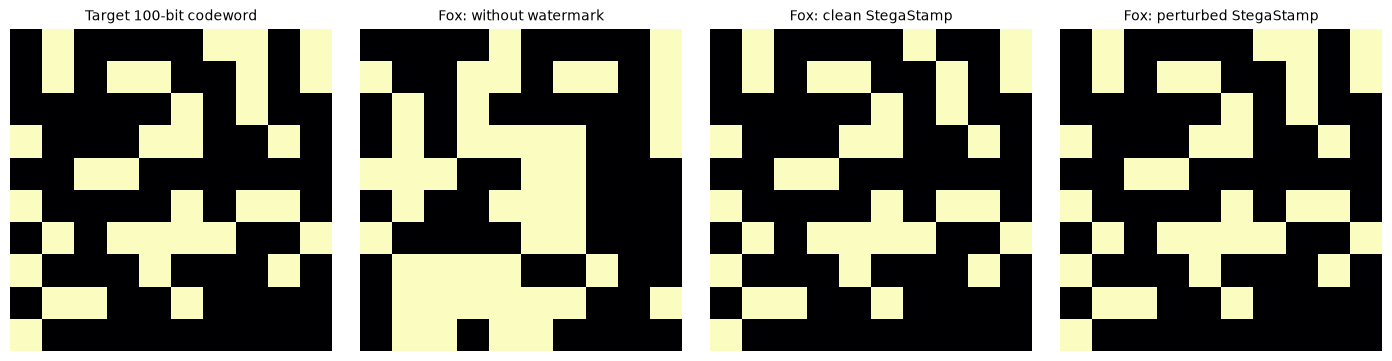

In [4]:
rows = []
index_labels = []
recovered_bits = {}

for label in samples:
    m_plain, b_plain = transformer.detect(samples[label])
    m_marked, b_marked = transformer.detect(marked_samples[label])
    img_pert = transformer.apply_perturbation(marked_samples[label], kind="all", strength=0.6)
    m_pert, b_pert = transformer.detect(img_pert)

    rows.extend([m_plain, m_marked, m_pert])
    index_labels.extend([
        f"{label}: without watermark",
        f"{label}: with watermark (clean)",
        f"{label}: with watermark (perturbed)",
    ])
    recovered_bits[label] = (b_plain, b_marked, b_pert)

df_metrics = pd.DataFrame(rows, index=index_labels)
display(df_metrics)

bits_plain, bits_marked, bits_corrupted = recovered_bits["Fox"]
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5), constrained_layout=True)
for ax, bits, title in zip(
    axes,
    [transformer.watermark, bits_plain, bits_marked, bits_corrupted],
    ["Target 100-bit codeword", "Fox: without watermark", "Fox: clean StegaStamp", "Fox: perturbed StegaStamp"],
):
    ax.imshow(bits.view(10, 10).numpy(), cmap="magma", vmin=0, vmax=1)
    ax.set_title(title, fontsize=10)
    ax.axis("off")
plt.show()

In [5]:
clean_rows = [df_metrics.loc[f"{k}: with watermark (clean)"] for k in samples]
pert_rows = [df_metrics.loc[f"{k}: with watermark (perturbed)"] for k in samples]
plain_rows = [df_metrics.loc[f"{k}: without watermark"] for k in samples]

checks = pd.Series({
    "All watermarked images detected (Fox, Cat, Dog)": all(bool(r["detected"]) for r in clean_rows),
    "All unmarked images rejected (Fox, Cat, Dog)": all(not bool(r["detected"]) for r in plain_rows),
    "Exact payload recovered on all clean images": all(r["decoded_payload"] == payload for r in clean_rows),
    "Exact payload recovered after physical perturbations (BCH ECC)": all(r["decoded_payload"] == payload for r in pert_rows),
    "Watermarked bit accuracy higher than unmarked on all images": all(
        c["bit_accuracy"] > p["bit_accuracy"] for c, p in zip(clean_rows, plain_rows)
    ),
}, name="Passed")

display(checks.to_frame())
print("PASS" if checks.all() else "FAIL")

,Passed
"All watermarked images detected (Fox, Cat, Dog)",True
"All unmarked images rejected (Fox, Cat, Dog)",True
Exact payload recovered on all clean images,True
Exact payload recovered after physical perturbations (BCH ECC),True
Watermarked bit accuracy higher than unmarked on all images,True


PASS
